In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder,MinMaxScaler,LabelEncoder
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (accuracy_score, classification_report, mean_absolute_error,mean_squared_error,
                             confusion_matrix, precision_score, recall_score, 
                             f1_score, roc_auc_score, roc_curve,log_loss)
import os
import sys
from sklearn.pipeline import Pipeline

In [2]:
cancer=pd.read_csv("D:\Machine Learning\Datasets\Cases\Wisconsin\BreastCancer.csv")

Without Scaler


In [3]:
X,y=cancer.drop('Class',axis=1),cancer['Class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=25,stratify=y)
print(f"Training samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")

Training samples: 489, Test samples: 210


In [4]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
lda=LinearDiscriminantAnalysis().set_output(transform='pandas')

lr=LogisticRegression()



In [5]:
lda_trn=lda.fit_transform(X_train,y_train)
lr.fit(lda_trn,y_train)
lda_tst=lda.transform(X_test)
y_pred=lr.predict(lda_tst)
print('Accuracy Score: ',accuracy_score(y_test,y_pred))

Accuracy Score:  0.9666666666666667


doing logistic regression with and without LDA on vehicle dataset

In [6]:
vehicle=pd.read_csv("D:\Machine Learning\Datasets\Cases\Vehicle_Silhouettes\Vehicle.csv")
vehicle

,Comp,Circ,D.Circ,Rad.Ra,Pr.Axis.Ra,Max.L.Ra,Scat.Ra,Elong,Pr.Axis.Rect,Max.L.Rect,Sc.Var.Maxis,Sc.Var.maxis,Ra.Gyr,Skew.Maxis,Skew.maxis,Kurt.maxis,Kurt.Maxis,Holl.Ra,Class
0,95,48,83,178,72,10,162,42,20,159,176,379,184,70,6,16,187,197,van
1,91,41,84,141,57,9,149,45,19,143,170,330,158,72,9,14,189,199,van
2,104,50,106,209,66,10,207,32,23,158,223,635,220,73,14,9,188,196,saab
3,93,41,82,159,63,9,144,46,19,143,160,309,127,63,6,10,199,207,van
4,85,44,70,205,103,52,149,45,19,144,241,325,188,127,9,11,180,183,bus
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
841,93,39,87,183,64,8,169,40,20,134,200,422,149,72,7,25,188,195,saab
842,89,46,84,163,66,11,159,43,20,159,173,368,176,72,1,20,186,197,van
843,106,54,101,222,67,12,222,30,25,173,228,721,200,70,3,4,187,201,saab
844,86,36,78,146,58,7,135,50,18,124,155,270,148,66,0,25,190,195,saab


In [7]:
from sklearn.model_selection import train_test_split

lr=LogisticRegression()
encoder=LabelEncoder()
X,y=vehicle.drop('Class',axis=1),vehicle['Class']
y=encoder.fit_transform(y)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=25,stratify=y)
print(f"Training samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")

Training samples: 592, Test samples: 254


In [8]:
lr.fit(X_train,y_train)
y_pred=lr.predict(X_test)

accuracy_score(y_test,y_pred)

d:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.7401574803149606

In [9]:
import warnings
warnings.filterwarnings('ignore')

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np

# Load the dataset (use raw string or forward slashes for Windows paths)
vehicle = pd.read_csv(r"D:\Machine Learning\Datasets\Cases\Vehicle_Silhouettes\Vehicle.csv")


# Prepare features and target
X = vehicle.drop('Class', axis=1)
y = vehicle['Class']

# Encode the target variable
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, 
    test_size=0.3, 
    random_state=25, 
    stratify=y_encoded
)

print(f"\nTraining samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")

# Train Logistic Regression model
lr = LogisticRegression(max_iter=1000, random_state=25)
lr.fit(X_train, y_train)

# Make predictions
y_pred = lr.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"\nAccuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")





Training samples: 592, Test samples: 254

Accuracy: 0.8386 (83.86%)


In [11]:
# Encode the target variable
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, 
    test_size=0.3, 
    random_state=25, 
    stratify=y_encoded
)

print(f"\nTraining samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")

lda=LinearDiscriminantAnalysis().set_output(transform='pandas')
lda_trn=lda.fit_transform(X_train,y_train)
# Train Logistic Regression model
lr = LogisticRegression(max_iter=1000, random_state=25)
lr.fit(lda_trn, y_train)
lda_tst=lda.transform(X_test)


# Make predictions
y_pred = lr.predict(lda_tst)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"\nAccuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")





Training samples: 592, Test samples: 254

Accuracy: 0.8189 (81.89%)


# Eigne vector and eigen values

In [12]:
df=pd.read_csv("D:\Machine Learning\Datasets\milk.csv",index_col=0)
milk=df.__deepcopy__()
milk.head()

,water,protein,fat,lactose,ash
Animal,,,,,
HORSE,90.1,2.6,1.0,6.9,0.35
ORANGUTAN,88.5,1.4,3.5,6.0,0.24
MONKEY,88.4,2.2,2.7,6.4,0.18
DONKEY,90.3,1.7,1.4,6.2,0.40
HIPPO,90.4,0.6,4.5,4.4,0.10


In [13]:
from sklearn.decomposition import PCA


scaler=StandardScaler().set_output(transform='pandas')
milk_scaled=scaler.fit_transform(milk)
pre_comp=PCA().set_output(transform='pandas')
pca_data=pre_comp.fit_transform(milk_scaled)
pca_data.var()

pca0    4.040412
pca1    0.924372
pca2    0.134291
pca3    0.102689
pca4    0.006570
dtype: float64

In [14]:
pre_comp.explained_variance_


array([4.0404117 , 0.92437238, 0.13429088, 0.1026886 , 0.00656977])

it will give percentage of particulat variance to total variance


In [15]:
pre_comp.explained_variance_/np.sum(pre_comp.explained_variance_)*100

array([77.57590469, 17.74794969,  2.57838496,  1.97162103,  0.12613963])

[12-12-2025 09:16:00] [pca.pca] [INFO] PCA reduction performed to capture at least 95.0% explained variance using 5 columns of the input data.
[12-12-2025 09:16:00] [pca.pca] [INFO] Fit using PCA.
[12-12-2025 09:16:00] [pca.pca] [INFO] Compute loadings and PCs.
[12-12-2025 09:16:00] [pca.pca] [INFO] Compute explained variance.
[12-12-2025 09:16:00] [pca.pca] [INFO] The top 2 principal component(s) explains >= 95.00% of the explained variance.
[12-12-2025 09:16:00] [pca.pca] [INFO] The PCA reduction is performed on 5 variables (columns) of the input dataframe.
[12-12-2025 09:16:00] [pca.pca] [INFO] Fit using PCA.
[12-12-2025 09:16:00] [pca.pca] [INFO] Compute loadings and PCs.
[12-12-2025 09:16:00] [pca.pca] [INFO] Outlier detection using Hotelling T2 test with alpha=[0.05] and n_components=[2]
[12-12-2025 09:16:00] [pca.pca] [INFO] Multiple test correction applied for Hotelling T2 test: [fdr_bh]
[12-12-2025 09:16:00] [pca.pca] [INFO] Outlier detection using SPE/DmodX with n_std=[3]
[12

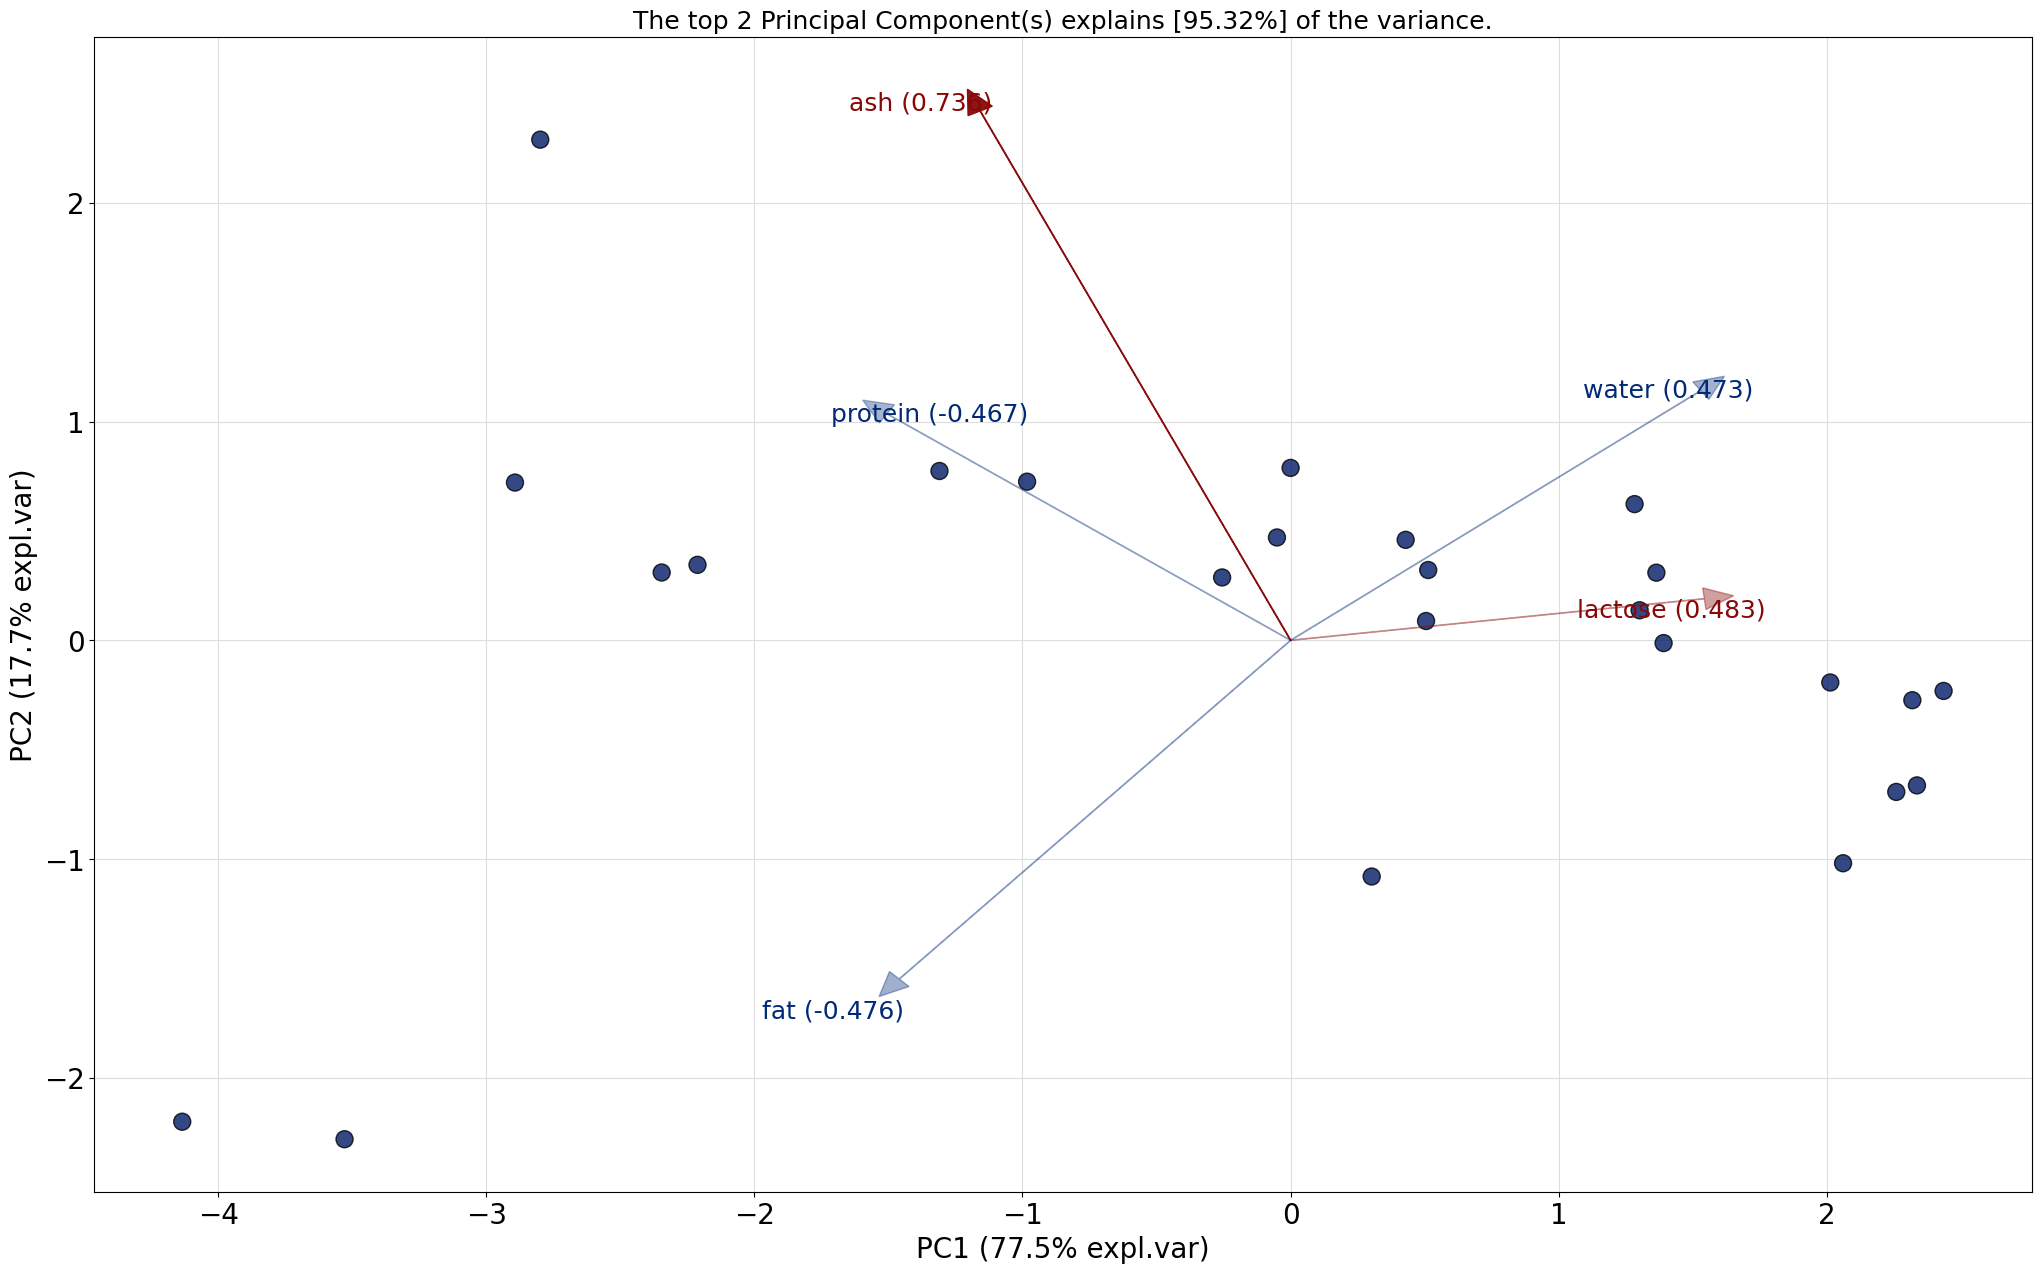

In [16]:
from pca import pca  # type: ignore
model=pca()
results=model.fit_transform(milk_scaled,col_labels=milk.columns,row_labels=list(milk.index))
model.biplot(label=True,legend=True)
for i in np.arange(0,milk.shape[0]):
    plt.Text(pca_data.values[i,0],pca_data.values[i,1],list(milk.index)[i])
plt.show()

# FOR Crime dataset

[12-12-2025 09:16:00] [pca.pca] [INFO] PCA reduction performed to capture at least 95.0% explained variance using 4 columns of the input data.
[12-12-2025 09:16:00] [pca.pca] [INFO] Fit using PCA.
[12-12-2025 09:16:00] [pca.pca] [INFO] Compute loadings and PCs.
[12-12-2025 09:16:00] [pca.pca] [INFO] Compute explained variance.
[12-12-2025 09:16:00] [pca.pca] [INFO] The top 3 principal component(s) explains >= 95.00% of the explained variance.
[12-12-2025 09:16:00] [pca.pca] [INFO] The PCA reduction is performed on 4 variables (columns) of the input dataframe.
[12-12-2025 09:16:00] [pca.pca] [INFO] Fit using PCA.
[12-12-2025 09:16:00] [pca.pca] [INFO] Compute loadings and PCs.
[12-12-2025 09:16:00] [pca.pca] [INFO] Outlier detection using Hotelling T2 test with alpha=[0.05] and n_components=[3]
[12-12-2025 09:16:00] [pca.pca] [INFO] Multiple test correction applied for Hotelling T2 test: [fdr_bh]
[12-12-2025 09:16:00] [pca.pca] [INFO] Outlier detection using SPE/DmodX with n_std=[3]
[12

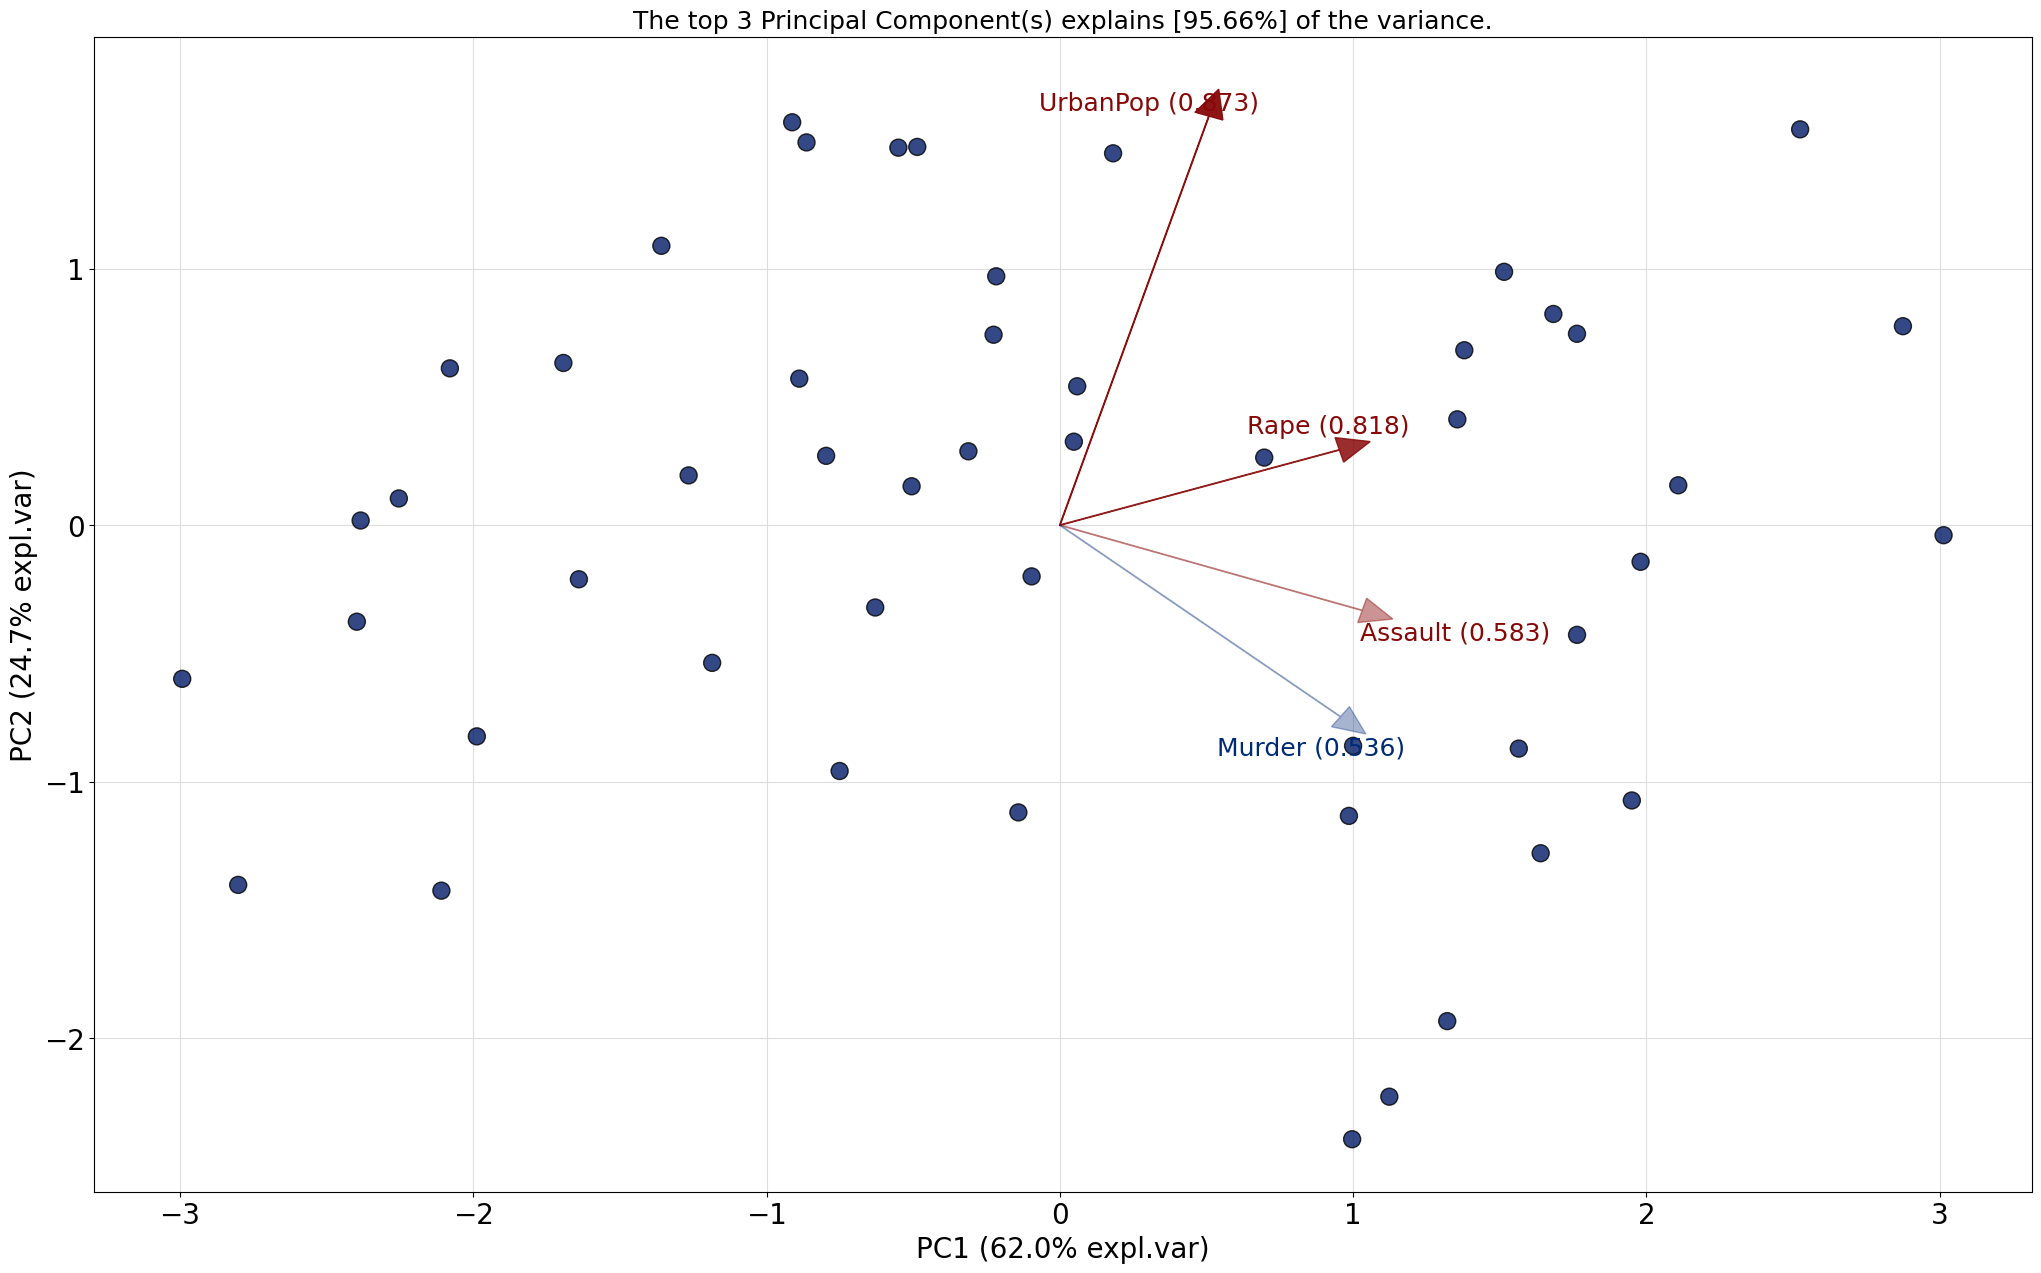

In [17]:
df=pd.read_csv("D:\\Machine Learning\\Datasets\\USArrests.csv",index_col=0)
crime=df.__deepcopy__()
crime.head()
from sklearn.decomposition import PCA


scaler=StandardScaler().set_output(transform='pandas')
crime_scaled=scaler.fit_transform(crime)
pre_comp=PCA().set_output(transform='pandas')
pca_data=pre_comp.fit_transform(crime_scaled)
pca_data.var()
pre_comp.explained_variance_



pre_comp.explained_variance_/np.sum(pre_comp.explained_variance_)*100
from pca import pca  # type: ignore
model=pca()
results=model.fit_transform(crime_scaled,col_labels=crime.columns,row_labels=list(crime.index))
model.biplot(label=True,legend=True)
for i in np.arange(0,crime.shape[0]):
    plt.Text(pca_data.values[i,0],pca_data.values[i,1],list(crime.index)[i])
plt.show()

In [18]:
pre_comp.explained_variance_/np.sum(pre_comp.explained_variance_)*100

array([62.00603948, 24.74412881,  8.91407951,  4.33575219])